In [4]:
# Step I : Import libraries
import tensorflow as tf
import matplotlib.pyplot as plt
import numpy as np

In [5]:
data = np.load('mnist.npz')
x_train, y_train = data['x_train'], data['y_train']
x_test, y_test = data['x_test'], data['y_test']

In [6]:
# Step III : Normalize the data
x_train = x_train / 255.0
x_test = x_test / 255.0

In [12]:
# Step IV : Build model
def build_model(regularization=None):
    model = tf.keras.Sequential([
        tf.keras.layers.Flatten(input_shape=(28, 28)),
        tf.keras.layers.Dense(128, activation='relu',
                              kernel_regularizer=regularization),
        tf.keras.layers.Dense(64, activation='relu'),
        tf.keras.layers.Dense(10, activation='softmax')
    ])

    model.compile(optimizer='adam',
                  loss='sparse_categorical_crossentropy',
                  metrics=['accuracy'])
    return model

In [13]:
# Step V : Train without L2 Regularization
model1 = build_model()
history1 = model1.fit(x_train, y_train, epochs=5,
                      batch_size=64, validation_split=0.2)

Epoch 1/5
750/750 ━━━━━━━━━━━━━━━━━━━━ 8s 7ms/step - accuracy: 0.9113 - loss: 0.3089 - val_accuracy: 0.9551 - val_loss: 0.1512
Epoch 2/5
750/750 ━━━━━━━━━━━━━━━━━━━━ 5s 6ms/step - accuracy: 0.9620 - loss: 0.1300 - val_accuracy: 0.9671 - val_loss: 0.1150
Epoch 3/5
750/750 ━━━━━━━━━━━━━━━━━━━━ 5s 7ms/step - accuracy: 0.9732 - loss: 0.0885 - val_accuracy: 0.9697 - val_loss: 0.1016
Epoch 4/5
750/750 ━━━━━━━━━━━━━━━━━━━━ 5s 6ms/step - accuracy: 0.9799 - loss: 0.0657 - val_accuracy: 0.9731 - val_loss: 0.0858
Epoch 5/5
750/750 ━━━━━━━━━━━━━━━━━━━━ 5s 7ms/step - accuracy: 0.9844 - loss: 0.0517 - val_accuracy: 0.9733 - val_loss: 0.0907


In [14]:
# Step VI : Train with L2 Regularization
model2 = build_model(tf.keras.regularizers.l2(0.001))
history2 = model2.fit(x_train, y_train, epochs=5,
                      batch_size=64, validation_split=0.2)

Epoch 1/5
750/750 ━━━━━━━━━━━━━━━━━━━━ 8s 8ms/step - accuracy: 0.9084 - loss: 0.4291 - val_accuracy: 0.9503 - val_loss: 0.2586
Epoch 2/5
750/750 ━━━━━━━━━━━━━━━━━━━━ 5s 7ms/step - accuracy: 0.9580 - loss: 0.2224 - val_accuracy: 0.9623 - val_loss: 0.1986
Epoch 3/5
750/750 ━━━━━━━━━━━━━━━━━━━━ 5s 7ms/step - accuracy: 0.9670 - loss: 0.1780 - val_accuracy: 0.9600 - val_loss: 0.1942
Epoch 4/5
750/750 ━━━━━━━━━━━━━━━━━━━━ 5s 7ms/step - accuracy: 0.9710 - loss: 0.1579 - val_accuracy: 0.9660 - val_loss: 0.1685
Epoch 5/5
750/750 ━━━━━━━━━━━━━━━━━━━━ 6s 8ms/step - accuracy: 0.9733 - loss: 0.1448 - val_accuracy: 0.9702 - val_loss: 0.1560


In [15]:
# Step VII : Train with Dropout
model3 = tf.keras.Sequential([
    tf.keras.layers.Flatten(input_shape=(28, 28)),
    tf.keras.layers.Dense(128, activation='relu'),
    tf.keras.layers.Dropout(0.3),
    tf.keras.layers.Dense(64, activation='relu'),
    tf.keras.layers.Dropout(0.2),
    tf.keras.layers.Dense(10, activation='softmax')
])

model3.compile(optimizer='adam',
               loss='sparse_categorical_crossentropy',
               metrics=['accuracy'])

history3 = model3.fit(x_train, y_train, epochs=5,
                      batch_size=64, validation_split=0.2)

Epoch 1/5
750/750 ━━━━━━━━━━━━━━━━━━━━ 8s 7ms/step - accuracy: 0.8597 - loss: 0.4616 - val_accuracy: 0.9517 - val_loss: 0.1698
Epoch 2/5
750/750 ━━━━━━━━━━━━━━━━━━━━ 5s 7ms/step - accuracy: 0.9350 - loss: 0.2211 - val_accuracy: 0.9620 - val_loss: 0.1291
Epoch 3/5
750/750 ━━━━━━━━━━━━━━━━━━━━ 5s 6ms/step - accuracy: 0.9484 - loss: 0.1754 - val_accuracy: 0.9683 - val_loss: 0.1117
Epoch 4/5
750/750 ━━━━━━━━━━━━━━━━━━━━ 5s 6ms/step - accuracy: 0.9556 - loss: 0.1452 - val_accuracy: 0.9713 - val_loss: 0.0955
Epoch 5/5
750/750 ━━━━━━━━━━━━━━━━━━━━ 5s 6ms/step - accuracy: 0.9610 - loss: 0.1286 - val_accuracy: 0.9726 - val_loss: 0.0969


313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9754 - loss: 0.0814
Without Regularization: 0.9753999710083008
313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.9729 - loss: 0.1476
With L2 Regularization: 0.9728999733924866
313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9730 - loss: 0.0910
With Dropout: 0.9729999899864197


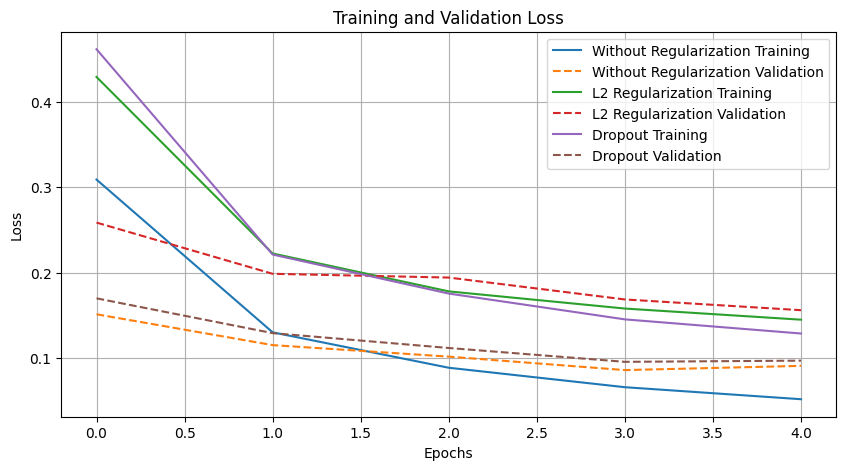

In [16]:
# Step VIII : Evaluate all models
print("Without Regularization:", model1.evaluate(x_test, y_test)[1])
print("With L2 Regularization:", model2.evaluate(x_test, y_test)[1])
print("With Dropout:", model3.evaluate(x_test, y_test)[1])

# Step IX : Plot Training and Validation Loss
plt.figure(figsize=(10, 5))

for history, name in [(history1, 'Without Regularization'),
                      (history2, 'L2 Regularization'),
                      (history3, 'Dropout')]:
    plt.plot(history.history['loss'], label=name+' Training')
    plt.plot(history.history['val_loss'], '--', label=name+' Validation')

plt.title('Training and Validation Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.grid()
plt.show()

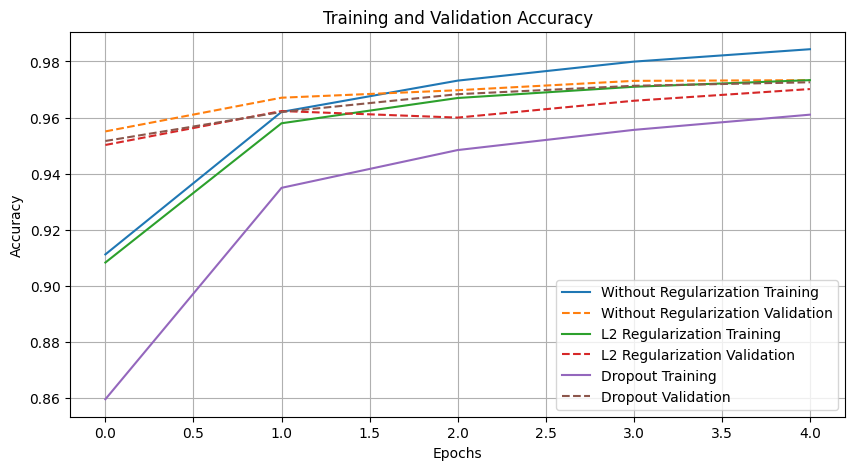

In [17]:
# Step X : Plot Training and Validation Accuracy
plt.figure(figsize=(10, 5))

for history, name in [(history1, 'Without Regularization'),
                      (history2, 'L2 Regularization'),
                      (history3, 'Dropout')]:
    plt.plot(history.history['accuracy'], label=name+' Training')
    plt.plot(history.history['val_accuracy'], '--', label=name+' Validation')

plt.title('Training and Validation Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.grid()
plt.show()


In [18]:
# Step II : Load the dataset
(x_train, y_train), (x_test, y_test) = (
    (np.fromfile('MNIST/train-images-idx3-ubyte', np.uint8)[16:].reshape(-1, 28, 28),
     np.fromfile('MNIST/train-labels-idx1-ubyte', np.uint8)[8:]),
    (np.fromfile('MNIST/t10k-images-idx3-ubyte', np.uint8)[16:].reshape(-1, 28, 28),
     np.fromfile('MNIST/t10k-labels-idx1-ubyte', np.uint8)[8:])
)